# Lab 6: Building ML models for ECG heartbeat classification

**AI in Healthcare · Unit II: Clinical applications of AI**

**Task:** five-class classification of **one already-extracted heartbeat** (187 samples at 125 Hz, scaled 0–1) into N, S, V, F or Q.
**Unit of analysis:** one beat, *not* one recording or one person.

> This is an educational exercise. The models here do not detect beats in a continuous recording, do not diagnose patients, and are **not** suitable for clinical use.

**Data source:** [ECG Heartbeat Categorization Dataset (Kaggle, shayanfazeli/heartbeat)](https://www.kaggle.com/datasets/shayanfazeli/heartbeat), which contains beats from the [MIT-BIH Arrhythmia Database](https://physionet.org/content/mitdb/1.0.0/) preprocessed by Kachuee et al. (2018). Only `mitbih_train.csv` and `mitbih_test.csv` are used; the PTB files are a different task.

**Data location:** the notebook reads from the relative folder `data/`. It uses `data/mitbih_train.csv` / `data/mitbih_test.csv` if they are present; otherwise it reads `data/mitbih_train.npz` / `data/mitbih_test.npz`. The `.npz` files are a lossless float32 copy of the same CSVs, made because my machine was short of disk space. Both give identical arrays (87,554 × 188 and 21,892 × 188). Data files are not part of the submission.

**Reproducibility:** one seed (`SEED = 42`) is used for the split and every model.

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix, accuracy_score, f1_score,
                             precision_recall_fscore_support)

SEED = 42
np.random.seed(SEED)
DATA_DIR = Path("data")
CLASS_NAMES = ["N", "S", "V", "F", "Q"]
CLASS_DESC = {"N": "normal / non-ectopic", "S": "supraventricular ectopic", "V": "ventricular ectopic",
              "F": "fusion", "Q": "paced / unclassifiable"}
FS = 125  # Hz
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100
warnings.filterwarnings("ignore", category=FutureWarning)


def load_split(name):
    csv = DATA_DIR / f"{name}.csv"
    if csv.exists():
        arr = pd.read_csv(csv, header=None).to_numpy(dtype=np.float32)
        src = csv
    else:
        src = DATA_DIR / f"{name}.npz"
        arr = np.load(src)["data"]
    df = pd.DataFrame(arr)
    df[187] = df[187].astype(int)
    print(f"loaded {src}  shape={df.shape}")
    return df


train_df = load_split("mitbih_train")
test_df = load_split("mitbih_test")

loaded data/mitbih_train.npz  shape=(87554, 188)
loaded data/mitbih_test.npz  shape=(21892, 188)


## Part A — Load and check the data

In [2]:
for name, df in [("train", train_df), ("test", test_df)]:
    print(f"{name}: shape={df.shape}, missing values={int(df.isna().sum().sum())}, "
          f"value range=[{df.iloc[:, :187].values.min():.3f}, {df.iloc[:, :187].values.max():.3f}]")

counts = pd.DataFrame({
    "class": CLASS_NAMES,
    "meaning": [CLASS_DESC[c] for c in CLASS_NAMES],
    "train_n": train_df[187].value_counts().sort_index().values,
    "test_n": test_df[187].value_counts().sort_index().values,
})
counts["train_%"] = (100 * counts.train_n / counts.train_n.sum()).round(2)
counts["test_%"] = (100 * counts.test_n / counts.test_n.sum()).round(2)
display(counts)
print("Total beats:", len(train_df) + len(test_df))

X_all = train_df.iloc[:, :187].to_numpy(np.float32)
y_all = train_df[187].to_numpy()
X_test = test_df.iloc[:, :187].to_numpy(np.float32)
y_test = test_df[187].to_numpy()
t_axis = np.arange(187) / FS * 1000  # ms

train: shape=(87554, 188), missing values=0, value range=[0.000, 1.000]
test: shape=(21892, 188), missing values=0, value range=[0.000, 1.000]


,class,meaning,train_n,test_n,train_%,test_%
0,N,normal / non-ectopic,72471,18118,82.77,82.76
1,S,supraventricular ectopic,2223,556,2.54,2.54
2,V,ventricular ectopic,5788,1448,6.61,6.61
3,F,fusion,641,162,0.73,0.74
4,Q,paced / unclassifiable,6431,1608,7.35,7.35


Total beats: 109446


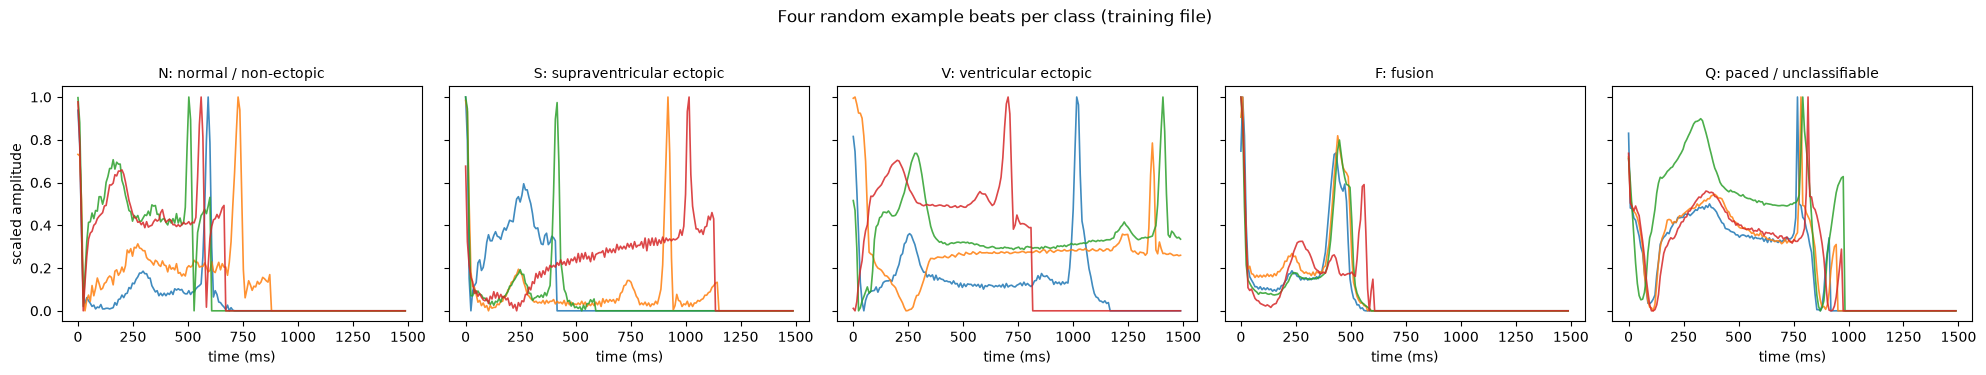

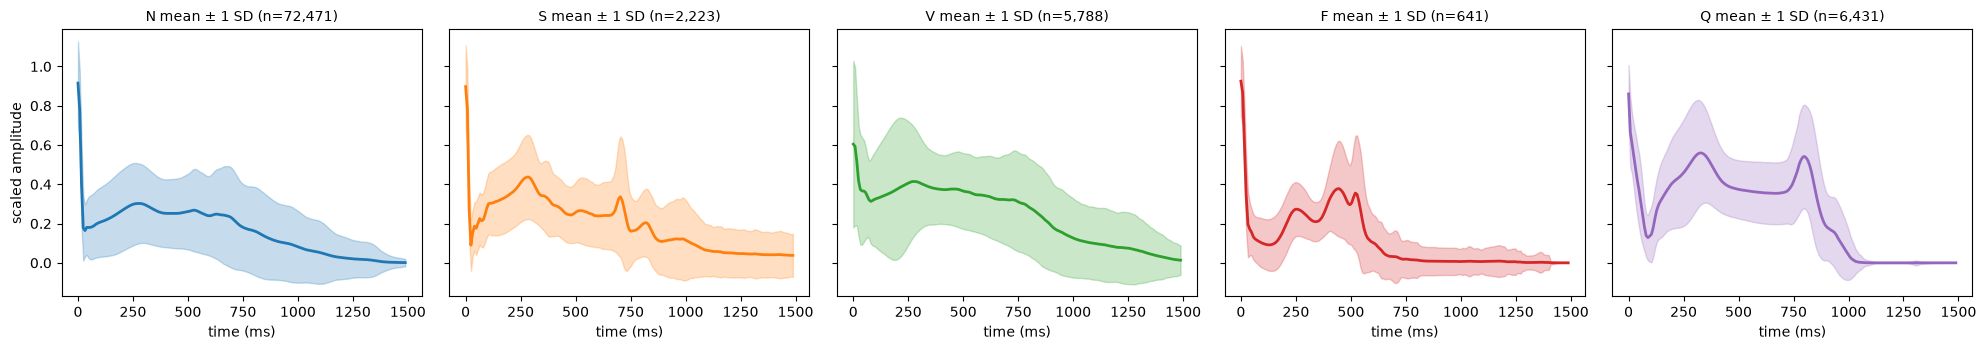

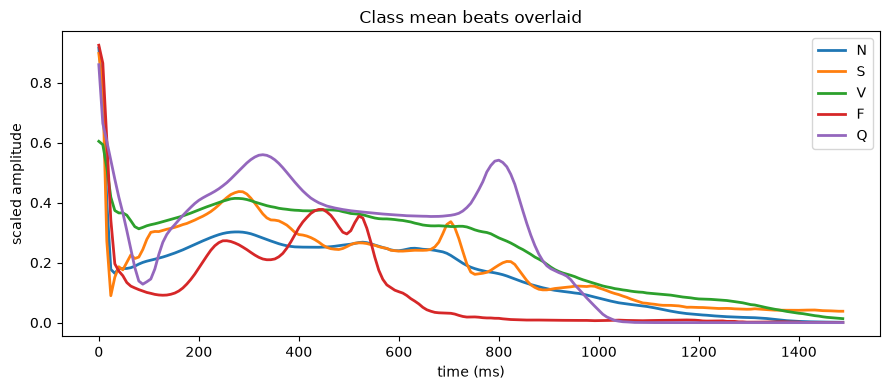

In [3]:
rng_plot = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6), sharey=True)
for c, ax in enumerate(axes):
    idx = rng_plot.choice(np.flatnonzero(y_all == c), 4, replace=False)
    for i in idx:
        ax.plot(t_axis, X_all[i], lw=1.2, alpha=0.85)
    ax.set_title(f"{CLASS_NAMES[c]}: {CLASS_DESC[CLASS_NAMES[c]]}", fontsize=10)
    ax.set_xlabel("time (ms)")
axes[0].set_ylabel("scaled amplitude")
plt.suptitle("Four random example beats per class (training file)", y=1.03)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6), sharey=True)
colors = sns.color_palette("tab10", 5)
for c, ax in enumerate(axes):
    Xc = X_all[y_all == c]
    mu, sd = Xc.mean(0), Xc.std(0)
    ax.plot(t_axis, mu, color=colors[c], lw=2)
    ax.fill_between(t_axis, mu - sd, mu + sd, color=colors[c], alpha=0.25)
    ax.set_title(f"{CLASS_NAMES[c]} mean ± 1 SD (n={len(Xc):,})", fontsize=10)
    ax.set_xlabel("time (ms)")
axes[0].set_ylabel("scaled amplitude")
plt.tight_layout(); plt.show()

# Overlay of class means for direct comparison
fig, ax = plt.subplots(figsize=(9, 4))
for c in range(5):
    ax.plot(t_axis, X_all[y_all == c].mean(0), label=CLASS_NAMES[c], color=colors[c], lw=2)
ax.set(xlabel="time (ms)", ylabel="scaled amplitude", title="Class mean beats overlaid")
ax.legend(); plt.tight_layout(); plt.show()

### Part A — answers

**Checks:** train 87,554 × 188, test 21,892 × 188, **no missing values**, and all signal values in [0, 1]. Class mix (train): **N 82.8%, S 2.5%, V 6.6%, F 0.7%, Q 7.3%**. The test file has the same proportions.

**What one row represents.** One row is **one heartbeat**: a fixed window starting at an R peak, resampled to 125 Hz, scaled to 0–1 and zero-padded to 187 samples. It is not a patient and not a recording. The 109,446 beats come from only **47 people (48 half-hour MIT-BIH records)**, i.e. on average more than 2,000 beats per person. Beats from one person are highly similar to each other, so they are far from independent observations, and the files carry no patient or record ID.

**Always predicting N** gives **82.8% accuracy** (validation: 0.828), with **0% sensitivity for F** and for every other abnormal class. A model can look "accurate" while never detecting any abnormal beat.

**By eye:** **Q** (mostly paced beats) is the most distinctive: a wide, slurred complex with a broad flat-topped mean shape and a high fraction of samples above 0.5. **V** is also distinctive: a wide QRS without the normal sharp, narrow R-wave shape, and a large variance band. The hardest pairs are **S vs N** (an S beat has near-normal QRS morphology; what distinguishes it is mainly that it comes *early*, which a single-beat window shows only indirectly) and **F vs N/V** (a fusion beat is literally a mix of a normal and a ventricular beat). The ±1 SD bands of these classes overlap heavily.

## Part B — Split and baseline

`mitbih_test.csv` is set aside and used **once**, in Part E. The training file is split 80/20 into *fit* and *validation* sets, stratified by class.

In [4]:
X_fit, X_val, y_fit, y_val = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
split_tbl = pd.DataFrame({
    "fit_n": np.bincount(y_fit), "fit_%": (100 * np.bincount(y_fit) / len(y_fit)).round(2),
    "val_n": np.bincount(y_val), "val_%": (100 * np.bincount(y_val) / len(y_val)).round(2),
}, index=CLASS_NAMES)
display(split_tbl)
print("fit:", X_fit.shape, " validation:", X_val.shape, " test (held out):", X_test.shape)

,fit_n,fit_%,val_n,val_%
N,57977,82.77,14494,82.77
S,1778,2.54,445,2.54
V,4630,6.61,1158,6.61
F,513,0.73,128,0.73
Q,5145,7.35,1286,7.34


fit: (70043, 187)  validation: (17511, 187)  test (held out): (21892, 187)


In [5]:
RESULTS, CMS, PREDS, TIMES = {}, {}, {}, {}


def evaluate(name, y_true, y_pred, store=True):
    """Per-class sensitivity/precision, macro F1 and accuracy; stores confusion matrix."""
    prec, rec, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=range(5), zero_division=0)
    row = {"accuracy": accuracy_score(y_true, y_pred), "macro_F1": f1.mean()}
    for i, c in enumerate(CLASS_NAMES):
        row[f"sens_{c}"] = rec[i]
    for i, c in enumerate(CLASS_NAMES):
        row[f"PPV_{c}"] = prec[i]
    if store:
        RESULTS[name] = row
        CMS[name] = confusion_matrix(y_true, y_pred, labels=range(5))
        PREDS[name] = y_pred
    return row


def plot_cm(cm, title, ax=None):
    """Row-normalised confusion matrix, annotated with count and row %."""
    ax = ax or plt.gca()
    norm = cm / cm.sum(1, keepdims=True)
    annot = np.array([[f"{cm[i, j]}\n{100 * norm[i, j]:.1f}%" for j in range(5)] for i in range(5)])
    sns.heatmap(norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 8})
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10)


def timed_fit(name, model, Xf, yf):
    t0 = time.time()
    model.fit(Xf, yf)
    TIMES[name] = time.time() - t0
    print(f"{name}: trained in {TIMES[name]:.1f}s")
    return model

Majority baseline: trained in 0.0s


LogReg: trained in 5.6s


LogReg balanced: trained in 7.7s


,accuracy,macro_F1,sens_N,sens_S,sens_V,sens_F,sens_Q,PPV_N,PPV_S,PPV_V,PPV_F,PPV_Q
Majority baseline,0.828,0.181,1.000,0.000,0.000,0.000,0.000,0.828,0.000,0.000,0.000,0.000
LogReg,0.913,0.657,0.982,0.447,0.332,0.289,0.890,0.925,0.822,0.629,0.673,0.936
LogReg balanced,0.674,0.482,0.644,0.694,0.737,0.852,0.935,0.973,0.152,0.298,0.080,0.718


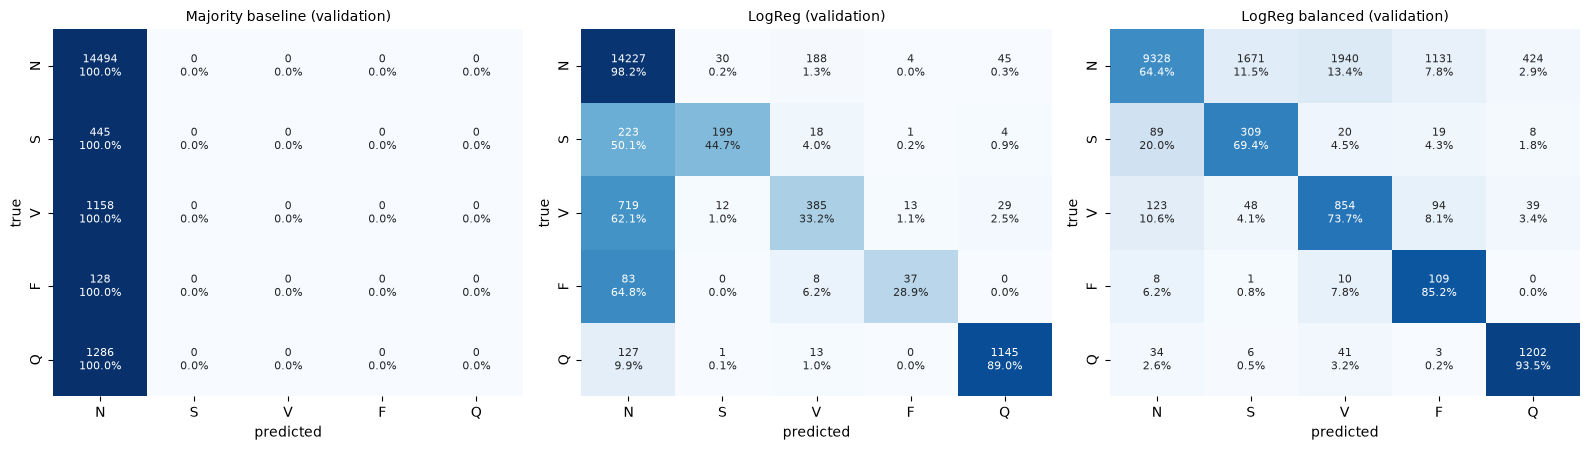

In [6]:
dummy = timed_fit("Majority baseline", DummyClassifier(strategy="most_frequent"), X_fit, y_fit)
evaluate("Majority baseline", y_val, dummy.predict(X_val))

logreg = timed_fit("LogReg", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)), X_fit, y_fit)
evaluate("LogReg", y_val, logreg.predict(X_val))

logreg_bal = timed_fit("LogReg balanced", make_pipeline(StandardScaler(),
                       LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)), X_fit, y_fit)
evaluate("LogReg balanced", y_val, logreg_bal.predict(X_val))

display(pd.DataFrame(RESULTS).T.round(3))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, n in zip(axes, ["Majority baseline", "LogReg", "LogReg balanced"]):
    plot_cm(CMS[n], f"{n} (validation)", ax)
plt.tight_layout(); plt.show()

### Part B — answers

The stratified 80/20 split keeps class proportions identical in fit and validation (e.g. F = 0.73% in both, i.e. 513 vs 128 beats). `mitbih_test.csv` stays untouched until Part E.

**Why not choose models on the test set?** Every decision made by looking at test results (which model, which hyper-parameters, which class weights, which epoch) fits the test set a little. After many comparisons, the best test score is biased upwards and no longer an honest estimate of performance on unseen data. The validation set absorbs that selection bias, and the test set is used once at the end so that its estimate stays unbiased.

**Baselines:**
- *Majority class:* accuracy 0.828, **macro F1 0.181**. This is the floor.
- *Logistic regression (unweighted):* accuracy 0.913 and macro F1 0.657, but it is heavily biased towards N. It detects only 33% of V and 29% of F beats.
- *Logistic regression with `class_weight="balanced"`:* sensitivity rose sharply for every minority class (S 0.45 → 0.69, V 0.33 → 0.74, **F 0.29 → 0.85**, Q 0.89 → 0.94). In the confusion matrix, mass moved out of the "predicted N" column into the minority columns.

**The cost:** N sensitivity fell from 0.98 to 0.64. About a third of normal beats are now flagged as abnormal, so minority-class **precision collapsed** (PPV for S 0.82 → 0.15, F 0.67 → 0.08). Accuracy fell to 0.674 and macro F1 to 0.482. Weighting the loss moves the decision boundary but cannot make a linear model on raw samples better at separating the classes. It just trades misses for false alarms.

## Part C — Stronger models

All models are trained on the **same fit set** and compared on the **same validation set**.

### C1. Random forest on the raw 187 values

In [7]:
rf_raw = timed_fit("RF raw", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED), X_fit, y_fit)
evaluate("RF raw", y_val, rf_raw.predict(X_val))
pd.Series(RESULTS["RF raw"]).round(3).to_frame("RF raw").T

RF raw: trained in 21.7s


,accuracy,macro_F1,sens_N,sens_S,sens_V,sens_F,sens_Q,PPV_N,PPV_S,PPV_V,PPV_F,PPV_Q
RF raw,0.975,0.875,0.998,0.613,0.891,0.609,0.956,0.975,0.975,0.967,0.918,0.993


### C2. Engineered features

Fourteen summary features per beat. The *non-padded length* is the index after which every value is zero, i.e. where the zero padding starts.

,max,argmax_ms,min,argmin_ms,mean,std,energy,length_ms,auc,max_slope,min_slope,line_length,skew,frac_above_0.5
cls,,,,,,,,,,,,,,
N,1.0,8.0,0.0,464.0,0.24,0.17,9.150000,848.0,0.20,0.30,-0.50,4.21,2.70,0.07
S,1.0,8.0,0.0,196.0,0.34,0.16,14.770000,856.0,0.29,0.28,-0.62,4.60,1.84,0.09
V,1.0,652.0,0.0,120.0,0.33,0.16,18.629999,912.0,0.32,0.19,-0.41,3.44,1.46,0.12
F,1.0,0.0,0.0,528.0,0.24,0.20,8.080000,624.0,0.15,0.26,-0.38,3.34,1.88,0.09
Q,1.0,776.0,0.0,224.0,0.41,0.19,23.330000,960.0,0.38,0.37,-0.46,4.38,0.12,0.27


RF features: trained in 4.8s


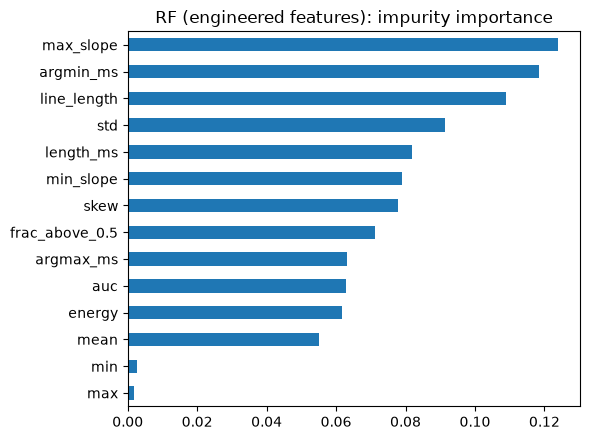

,accuracy,macro_F1,sens_N,sens_S,sens_V,sens_F,sens_Q,PPV_N,PPV_S,PPV_V,PPV_F,PPV_Q
RF raw,0.975,0.875,0.998,0.613,0.891,0.609,0.956,0.975,0.975,0.967,0.918,0.993
RF features,0.973,0.865,0.997,0.580,0.890,0.602,0.946,0.973,0.949,0.966,0.906,0.992


In [8]:
def nonpadded_length(X, tol=1e-6):
    nz = np.abs(X) > tol
    # position of last non-zero value + 1 (beats are right-padded with zeros)
    return np.where(nz.any(1), X.shape[1] - np.argmax(nz[:, ::-1], axis=1), 0)


def beat_features(X):
    L = nonpadded_length(X)
    mask = np.arange(X.shape[1])[None, :] < L[:, None]
    Xm = np.where(mask, X, np.nan)
    d = np.diff(X, axis=1)
    feats = {
        "max": X.max(1), "argmax_ms": X.argmax(1) / FS * 1000,
        "min": np.nanmin(Xm, 1), "argmin_ms": np.nanargmin(Xm, 1) / FS * 1000,
        "mean": np.nanmean(Xm, 1), "std": np.nanstd(Xm, 1),
        "energy": (X ** 2).sum(1), "length_ms": L / FS * 1000,
        "auc": np.nansum(Xm, 1) / FS,
        "max_slope": d.max(1), "min_slope": d.min(1),
        "line_length": np.abs(d).sum(1),
        "skew": pd.DataFrame(Xm).skew(axis=1).to_numpy(),
        "frac_above_0.5": (X > 0.5).sum(1) / np.maximum(L, 1),
    }
    return pd.DataFrame(feats)

F_fit, F_val, F_test = beat_features(X_fit), beat_features(X_val), beat_features(X_test)
display(F_fit.assign(cls=[CLASS_NAMES[c] for c in y_fit]).groupby("cls").median().round(2).loc[CLASS_NAMES])

rf_feat = timed_fit("RF features", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED), F_fit, y_fit)
evaluate("RF features", y_val, rf_feat.predict(F_val))

imp = pd.Series(rf_feat.feature_importances_, index=F_fit.columns).sort_values()
imp.plot.barh(figsize=(6, 4.5), title="RF (engineered features): impurity importance"); plt.tight_layout(); plt.show()
display(pd.DataFrame({k: RESULTS[k] for k in ["RF raw", "RF features"]}).T.round(3))

### C3. Neural networks on the raw signal

**1D CNN.** PyTorch could not be installed on my machine (the disk was almost full), so I implemented a small 1D CNN directly in NumPy. It has the architecture the lab recommends: three *convolution → ReLU → max-pool* blocks (16, 32, 32 filters; kernels 7, 5, 3), a dense layer of 64 units with dropout 0.3, and a 5-class softmax output. It is trained with mini-batch Adam (batch size 128, learning rate 1e-3) on cross-entropy, and **early stopping on validation macro F1** (patience 4) restores the best epoch. I verified the backpropagation code against numerical gradients before using it; the maximum absolute error was about 1e-8.

I also train scikit-learn's `MLPClassifier` (a fully connected network, no convolutions) as a second network built from a standard library.

In [9]:
import time
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view


class Conv1D:
    """'Same'-padded 1D convolution, channels-last tensors of shape (N, L, C)."""
    def __init__(self, c_in, c_out, k, rng):
        self.k, self.c_in, self.c_out = k, c_in, c_out
        self.W = (rng.standard_normal((c_in * k, c_out)) * np.sqrt(2.0 / (c_in * k))).astype(np.float32)
        self.b = np.zeros(c_out, np.float32)

    def forward(self, x):
        n, L, _ = x.shape
        p = self.k // 2
        xp = np.pad(x, ((0, 0), (p, self.k - 1 - p), (0, 0)))
        cols = sliding_window_view(xp, self.k, axis=1)          # (N, L, C_in, k)
        self.cols = cols.reshape(n, L, self.c_in * self.k)       # copy -> im2col
        self.x_shape = x.shape
        return self.cols @ self.W + self.b

    def backward(self, dout):
        n, L, _ = self.x_shape
        self.dW = self.cols.reshape(-1, self.c_in * self.k).T @ dout.reshape(-1, self.c_out)
        self.db = dout.sum(axis=(0, 1))
        dcols = (dout @ self.W.T).reshape(n, L, self.c_in, self.k)
        p = self.k // 2
        dxp = np.zeros((n, L + self.k - 1, self.c_in), np.float32)
        for j in range(self.k):                                   # col2im: scatter-add
            dxp[:, j:j + L, :] += dcols[:, :, :, j]
        return dxp[:, p:p + L, :]

    def params(self):
        return [(self.W, "dW"), (self.b, "db")]


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, d):
        return d * self.mask

    def params(self):
        return []


class MaxPool1D:
    """Non-overlapping max pooling of size 2 along the length axis."""
    def forward(self, x):
        n, L, c = x.shape
        self.L = L
        Lh = L // 2
        xr = x[:, :2 * Lh].reshape(n, Lh, 2, c)
        self.arg = xr.argmax(axis=2)
        return xr.max(axis=2)

    def backward(self, d):
        n, Lh, c = d.shape
        dx = np.zeros((n, self.L, c), np.float32)
        dr = dx[:, :2 * Lh].reshape(n, Lh, 2, c)
        np.put_along_axis(dr, self.arg[:, :, None, :], d[:, :, None, :], axis=2)
        return dx

    def params(self):
        return []


class Flatten:
    def forward(self, x):
        self.shape = x.shape
        return x.reshape(x.shape[0], -1)

    def backward(self, d):
        return d.reshape(self.shape)

    def params(self):
        return []


class Dense:
    def __init__(self, d_in, d_out, rng):
        self.W = (rng.standard_normal((d_in, d_out)) * np.sqrt(2.0 / d_in)).astype(np.float32)
        self.b = np.zeros(d_out, np.float32)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, d):
        self.dW = self.x.T @ d
        self.db = d.sum(axis=0)
        return d @ self.W.T

    def params(self):
        return [(self.W, "dW"), (self.b, "db")]


class Dropout:
    def __init__(self, p, rng):
        self.p, self.rng, self.training = p, rng, True

    def forward(self, x):
        if not self.training or self.p == 0:
            return x
        self.mask = (self.rng.random(x.shape) >= self.p).astype(np.float32) / (1 - self.p)
        return x * self.mask

    def backward(self, d):
        return d * self.mask if self.training and self.p > 0 else d

    def params(self):
        return []


class NumpyCNN1D:
    """Small 1D CNN: [Conv-ReLU-Pool] x 3 -> Dense(64) -> Dropout -> Dense(n_classes).
    Trained with mini-batch Adam on softmax cross-entropy; early stopping on validation macro F1."""

    def __init__(self, length=187, n_classes=5, channels=(16, 32, 32), kernels=(7, 5, 3), hidden=64,
                 dropout=0.3, seed=42):
        rng = np.random.default_rng(seed)
        self.rng = rng
        layers, c_in, L = [], 1, length
        for c_out, k in zip(channels, kernels):
            layers += [Conv1D(c_in, c_out, k, rng), ReLU(), MaxPool1D()]
            c_in, L = c_out, L // 2
        layers += [Flatten(), Dense(c_in * L, hidden, rng), ReLU(), Dropout(dropout, rng),
                   Dense(hidden, n_classes, rng)]
        self.layers = layers
        self.n_classes = n_classes

    def _set_training(self, flag):
        for l in self.layers:
            if isinstance(l, Dropout):
                l.training = flag

    def _forward(self, x):
        for l in self.layers:
            x = l.forward(x)
        return x

    def _backward(self, d):
        for l in reversed(self.layers):
            d = l.backward(d)

    def predict_proba(self, X, batch=2048):
        self._set_training(False)
        out = []
        for i in range(0, len(X), batch):
            z = self._forward(X[i:i + batch, :, None].astype(np.float32))
            z = z - z.max(axis=1, keepdims=True)
            e = np.exp(z)
            out.append(e / e.sum(axis=1, keepdims=True))
        return np.vstack(out)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    def fit(self, X, y, X_val, y_val, epochs=30, batch=128, lr=1e-3, patience=4, score_fn=None,
            class_weight=None, verbose=True):
        params = [(p, l, g) for l in self.layers for p, g in l.params()]
        m = [np.zeros_like(p) for p, _, _ in params]
        v = [np.zeros_like(p) for p, _, _ in params]
        b1, b2, eps, t = 0.9, 0.999, 1e-8, 0
        cw = np.ones(self.n_classes, np.float32) if class_weight is None else np.asarray(class_weight, np.float32)
        best, best_state, wait = -np.inf, None, 0
        self.history = []
        n = len(X)
        for epoch in range(1, epochs + 1):
            t0 = time.time()
            self._set_training(True)
            order = self.rng.permutation(n)
            total_loss = 0.0
            for i in range(0, n, batch):
                idx = order[i:i + batch]
                xb, yb = X[idx, :, None].astype(np.float32), y[idx]
                z = self._forward(xb)
                z = z - z.max(axis=1, keepdims=True)
                p = np.exp(z); p /= p.sum(axis=1, keepdims=True)
                w = cw[yb]
                total_loss += float(-(w * np.log(p[np.arange(len(yb)), yb] + 1e-12)).sum())
                d = p.copy(); d[np.arange(len(yb)), yb] -= 1
                d *= (w / w.sum())[:, None]
                self._backward(d.astype(np.float32))
                t += 1
                for j, (prm, layer, gname) in enumerate(params):
                    g = getattr(layer, gname)
                    m[j] = b1 * m[j] + (1 - b1) * g
                    v[j] = b2 * v[j] + (1 - b2) * g * g
                    prm -= (lr * (m[j] / (1 - b1 ** t)) / (np.sqrt(v[j] / (1 - b2 ** t)) + eps)).astype(np.float32)
            val_pred = self.predict(X_val)
            score = score_fn(y_val, val_pred)
            self.history.append({"epoch": epoch, "train_loss": total_loss / n, "val_macro_f1": score,
                                 "seconds": time.time() - t0})
            if verbose:
                print(f"epoch {epoch:2d}  train_loss={total_loss / n:.4f}  val_macro_F1={score:.4f}  ({time.time() - t0:.0f}s)")
            if score > best:
                best, wait = score, 0
                best_state = [prm.copy() for prm, _, _ in params]
                self.best_epoch = epoch
            else:
                wait += 1
                if wait >= patience:
                    if verbose:
                        print(f"early stopping: no improvement for {patience} epochs; restoring epoch {self.best_epoch}")
                    break
        for (prm, _, _), saved in zip(params, best_state):
            prm[...] = saved
        return self

epoch  1  train_loss=0.2656  val_macro_F1=0.8109  (7s)


epoch  2  train_loss=0.1335  val_macro_F1=0.8290  (7s)


epoch  3  train_loss=0.1083  val_macro_F1=0.8393  (7s)


epoch  4  train_loss=0.0943  val_macro_F1=0.8695  (7s)


epoch  5  train_loss=0.0837  val_macro_F1=0.8737  (7s)


epoch  6  train_loss=0.0778  val_macro_F1=0.8922  (7s)


... (9 outputs left out)

epoch 16  train_loss=0.0431  val_macro_F1=0.9116  (8s)


epoch 17  train_loss=0.0422  val_macro_F1=0.9166  (8s)


epoch 18  train_loss=0.0397  val_macro_F1=0.9122  (7s)


epoch 19  train_loss=0.0389  val_macro_F1=0.9138  (7s)
early stopping: no improvement for 4 epochs; restoring epoch 15
1D CNN trained in 138s; best epoch = 15


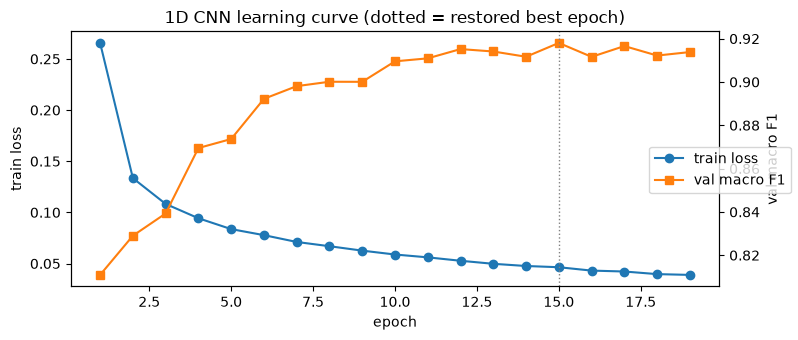

In [10]:
macro_f1 = lambda a, b: f1_score(a, b, average="macro")
cnn = NumpyCNN1D(seed=SEED)
t0 = time.time()
cnn.fit(X_fit, y_fit, X_val, y_val, epochs=40, batch=128, lr=1e-3, patience=4, score_fn=macro_f1)
TIMES["1D CNN (NumPy)"] = time.time() - t0
print(f"1D CNN trained in {TIMES['1D CNN (NumPy)']:.0f}s; best epoch = {cnn.best_epoch}")
cnn_val_proba = cnn.predict_proba(X_val)
evaluate("1D CNN (NumPy)", y_val, cnn_val_proba.argmax(1))

hist = pd.DataFrame(cnn.history)
fig, ax1 = plt.subplots(figsize=(8, 3.5))
ax1.plot(hist.epoch, hist.train_loss, "o-", label="train loss"); ax1.set_xlabel("epoch"); ax1.set_ylabel("train loss")
ax2 = ax1.twinx(); ax2.plot(hist.epoch, hist.val_macro_f1, "s-", color="C1", label="val macro F1"); ax2.set_ylabel("val macro F1")
ax2.axvline(cnn.best_epoch, color="grey", ls=":", lw=1)
fig.legend(loc="center right"); ax1.set_title("1D CNN learning curve (dotted = restored best epoch)")
plt.tight_layout(); plt.show()

In [11]:
mlp = timed_fit("MLP (sklearn)", MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True, validation_fraction=0.1,
                                               n_iter_no_change=5, max_iter=200, random_state=SEED), X_fit, y_fit)
evaluate("MLP (sklearn)", y_val, mlp.predict(X_val))
pd.DataFrame(TIMES, index=["training seconds"]).T.round(1)

MLP (sklearn): trained in 4.3s


,training seconds
Majority baseline,0.0
LogReg,5.6
LogReg balanced,7.7
RF raw,21.7
RF features,4.8
1D CNN (NumPy),138.4
MLP (sklearn),4.3


### The padding question: is the model learning physiology or data preparation?

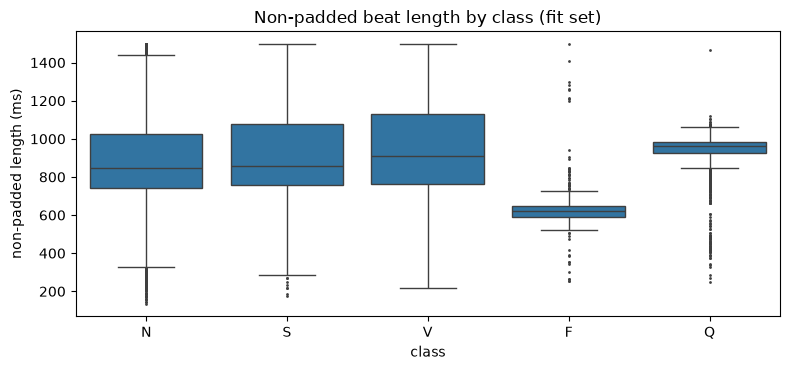

,accuracy,macro_F1,sens_N,sens_S,sens_V,sens_F,sens_Q
RF raw (reference),0.975,0.875,0.998,0.613,0.891,0.609,0.956
RF length only,0.828,0.181,1.000,0.000,0.000,0.000,0.000
RF first 0.5 s only,0.974,0.865,0.998,0.602,0.894,0.547,0.953
1D CNN (reference),0.985,0.918,0.994,0.780,0.976,0.742,0.991
"1D CNN, padding moved earlier",0.972,0.867,0.982,0.728,0.965,0.680,0.984


97.6% of fit beats are at least 63 samples long
CNN predictions that change when only the padding boundary moves: 1.96%


In [12]:
L_fit_ms, L_val_ms = F_fit["length_ms"], F_val["length_ms"]
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(x=[CLASS_NAMES[c] for c in y_fit], y=L_fit_ms, order=CLASS_NAMES, ax=ax, fliersize=1)
ax.set(xlabel="class", ylabel="non-padded length (ms)", title="Non-padded beat length by class (fit set)")
plt.tight_layout(); plt.show()

# Check 1: how much can a model learn from the padding length ALONE?
rf_len = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED).fit(L_fit_ms.to_frame(), y_fit)
len_only = evaluate("(check) RF length only", y_val, rf_len.predict(L_val_ms.to_frame()), store=False)

# Check 2: hide the length - keep only the first 0.5 s (63 samples) after the R peak, which
# every beat has, and zero the rest; then retrain the raw-signal RF.
W = 63
short_ok = (nonpadded_length(X_fit) >= W).mean()
Xf_cut, Xv_cut = X_fit.copy(), X_val.copy()
Xf_cut[:, W:] = 0; Xv_cut[:, W:] = 0
rf_cut = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED).fit(Xf_cut, y_fit)
cut = evaluate("(check) RF first 0.5 s only", y_val, rf_cut.predict(Xv_cut), store=False)

# Check 3: does the CNN's prediction change if we only alter where the padding starts?
# Truncate every validation beat 10 samples (80 ms) earlier, i.e. move the padding boundary.
Lv = nonpadded_length(X_val)
X_val_trunc = X_val.copy()
for i, l in enumerate(Lv):
    X_val_trunc[i, max(l - 10, W):] = 0
cnn_trunc_pred = cnn.predict(X_val_trunc)
flip = (cnn_trunc_pred != cnn_val_proba.argmax(1)).mean()
trunc = evaluate("(check) CNN, padding moved 80 ms earlier", y_val, cnn_trunc_pred, store=False)

pad_tbl = pd.DataFrame({"RF raw (reference)": RESULTS["RF raw"], "RF length only": len_only,
                        "RF first 0.5 s only": cut, "1D CNN (reference)": RESULTS["1D CNN (NumPy)"],
                        "1D CNN, padding moved earlier": trunc}).T
display(pad_tbl[["accuracy", "macro_F1"] + [f"sens_{c}" for c in CLASS_NAMES]].round(3))
print(f"{100 * short_ok:.1f}% of fit beats are at least {W} samples long")
print(f"CNN predictions that change when only the padding boundary moves: {100 * flip:.2f}%")

### Part C — answers

**Training times (CPU, Apple M3):** majority baseline < 0.1 s, logistic regression ~5–7 s, RF on raw values 20 s, RF on 14 features 4 s, MLP 4 s, **1D CNN 134 s** (19 epochs × ~7 s; early stopping restored epoch 15).

**Raw values vs engineered features.** The raw-value RF did slightly better (macro F1 **0.875** vs **0.865**; S sensitivity 0.61 vs 0.58). The features were 5× faster to train and nearly as good with 14 numbers instead of 187. A possible reason for the small gap: the summary features throw away the *shape and timing detail* of the waveform (P-wave presence, QRS width, ST/T morphology, the position of the next R peak), which matter most for the hard classes S and F. A forest on raw samples can pick up some of that from individual time points.

**What a 1D CNN can learn that summary features cannot.** Convolution filters learn **local shape patterns** (a narrow vs wide QRS, a missing or abnormal P wave, notches, T-wave inversion) *wherever they occur* in the window. Stacked layers then combine them into larger patterns (shape + relative timing). That is translation-tolerant, learned feature extraction, not a fixed list. The CNN had the best validation macro F1 (**0.918**), with the largest gains on the hard classes: S 0.61 → 0.78 and F 0.61 → 0.74 sensitivity vs RF raw. The fully connected MLP (0.883) sits between RF and the CNN, which suggests the convolution structure itself helps.

**The padding question.** Non-padded length (essentially the time to the *next* R peak, since each window ends at the next beat) differs by class: F beats have the shortest median (624 ms) and Q the longest (960 ms). The models could therefore exploit *how the data were prepared* (the RR interval encoded as padding) rather than beat morphology. My checks:
1. **Length alone** is weak on its own here: an RF on length only predicts N for everything (macro F1 0.181). Length distributions overlap too much for it to separate classes alone.
2. **Hiding the length:** keeping only the first 0.5 s (63 samples, which 97.6% of beats have in full) and zeroing the rest lowered RF macro F1 only slightly (0.875 → 0.865), mostly through F (0.61 → 0.55). Most of the signal is in beat morphology.
3. **Moving the padding boundary** 80 ms earlier in the validation beats, without changing anything else, changed **2.0% of the CNN's predictions** and lowered its macro F1 from 0.918 to 0.867, mainly for S and F.

**Conclusion:** the models mostly learn waveform shape, but partly rely on where the zeros start. That is genuinely useful timing information (the RR interval is clinically relevant for S beats), but it is delivered through a preprocessing artefact. A model fed differently segmented beats, e.g. from another beat detector, could behave differently. A cleaner design would supply RR intervals as explicit features, as de Chazal et al. (2004) did, and use fixed windows.

## Part D — Evaluate on the validation set

,accuracy,macro_F1,sens_N,sens_S,sens_V,sens_F,sens_Q,PPV_N,PPV_S,PPV_V,PPV_F,PPV_Q,train_seconds
1D CNN (NumPy),0.985,0.918,0.994,0.780,0.976,0.742,0.991,0.991,0.911,0.935,0.888,0.997,138.398
MLP (sklearn),0.977,0.883,0.994,0.692,0.913,0.672,0.976,0.982,0.865,0.946,0.851,0.983,4.286
RF raw,0.975,0.875,0.998,0.613,0.891,0.609,0.956,0.975,0.975,0.967,0.918,0.993,21.706
RF features,0.973,0.865,0.997,0.580,0.890,0.602,0.946,0.973,0.949,0.966,0.906,0.992,4.754
LogReg,0.913,0.657,0.982,0.447,0.332,0.289,0.890,0.925,0.822,0.629,0.673,0.936,5.567
LogReg balanced,0.674,0.482,0.644,0.694,0.737,0.852,0.935,0.973,0.152,0.298,0.080,0.718,7.665
Majority baseline,0.828,0.181,1.000,0.000,0.000,0.000,0.000,0.828,0.000,0.000,0.000,0.000,0.001


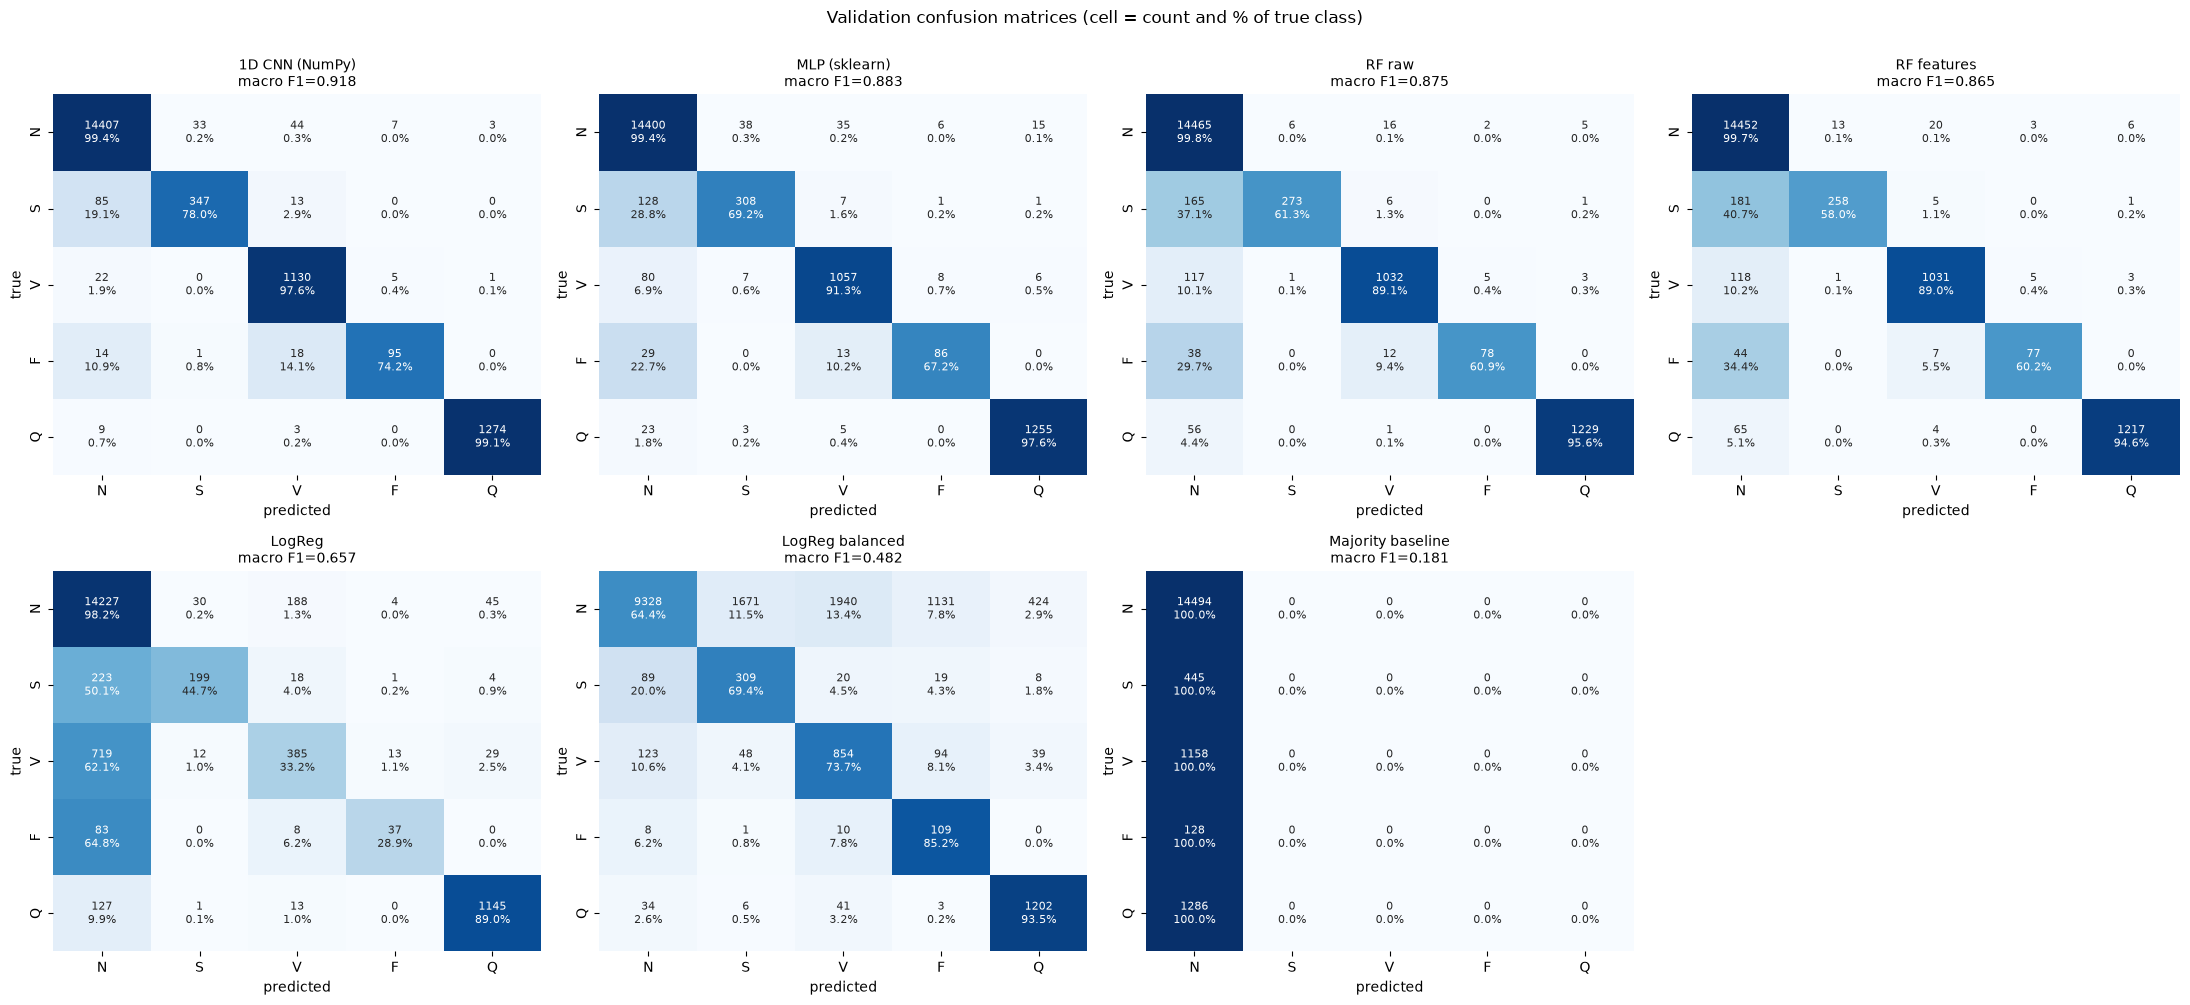

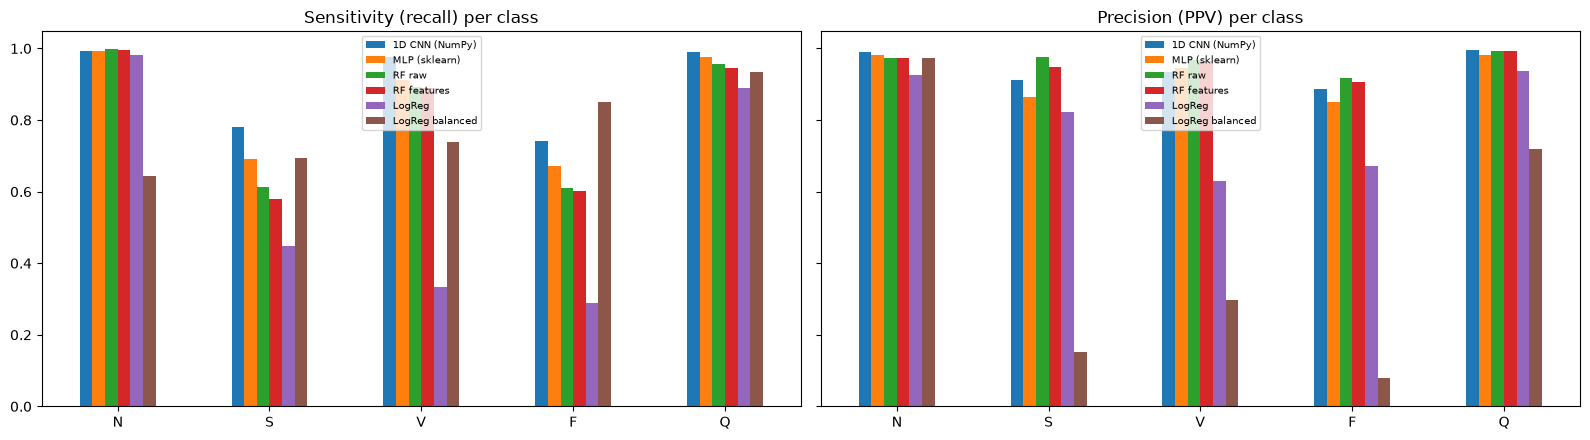

Selected model (highest validation macro F1): 1D CNN (NumPy)


In [13]:
comparison = pd.DataFrame(RESULTS).T
comparison["train_seconds"] = pd.Series(TIMES)
comparison = comparison.sort_values("macro_F1", ascending=False)
display(comparison.round(3))

models_plot = list(comparison.index)
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, n in zip(axes.flat, models_plot):
    plot_cm(CMS[n], f"{n}\nmacro F1={RESULTS[n]['macro_F1']:.3f}", ax)
for ax in axes.flat[len(models_plot):]:
    ax.axis("off")
plt.suptitle("Validation confusion matrices (cell = count and % of true class)", y=1.0)
plt.tight_layout(); plt.show()

# Per-class sensitivity / PPV chart
sens_df = comparison[[f"sens_{c}" for c in CLASS_NAMES]].drop(index="Majority baseline")
sens_df.columns = CLASS_NAMES
ppv_df = comparison[[f"PPV_{c}" for c in CLASS_NAMES]].drop(index="Majority baseline")
ppv_df.columns = CLASS_NAMES
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
sens_df.T.plot.bar(ax=axes[0], rot=0, title="Sensitivity (recall) per class"); axes[0].legend(fontsize=7)
ppv_df.T.plot.bar(ax=axes[1], rot=0, title="Precision (PPV) per class"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

best_name = comparison.index[0]
print("Selected model (highest validation macro F1):", best_name)

### Model choice

I select the **1D CNN**. It has the highest validation **macro F1 (0.918)** and accuracy (0.985). Among the models with usable precision it has the best sensitivity on every abnormal class (S 0.78, V 0.98, F 0.74, Q 0.99), while PPV stays ≥ 0.89 for every class. Only the balanced logistic regression finds more F beats (0.85), and it pays with an F precision of 0.08. The RF has higher PPV for S and F (0.98 and 0.92) but misses many more of those beats. For a review-prioritisation aid, sensitivity to abnormal beats matters more, so the CNN's balance is preferable. Its drawbacks: ~6× longer training than the RF, less interpretable than features, and its validation score is slightly optimistic because the validation set was also used for early stopping.

Most frequent confusion for 1D CNN (NumPy): true S predicted as N (85 beats)
Most confused unordered pairs: [('N<->S', np.int64(118)), ('N<->V', np.int64(66)), ('V<->F', np.int64(23)), ('N<->F', np.int64(21))]


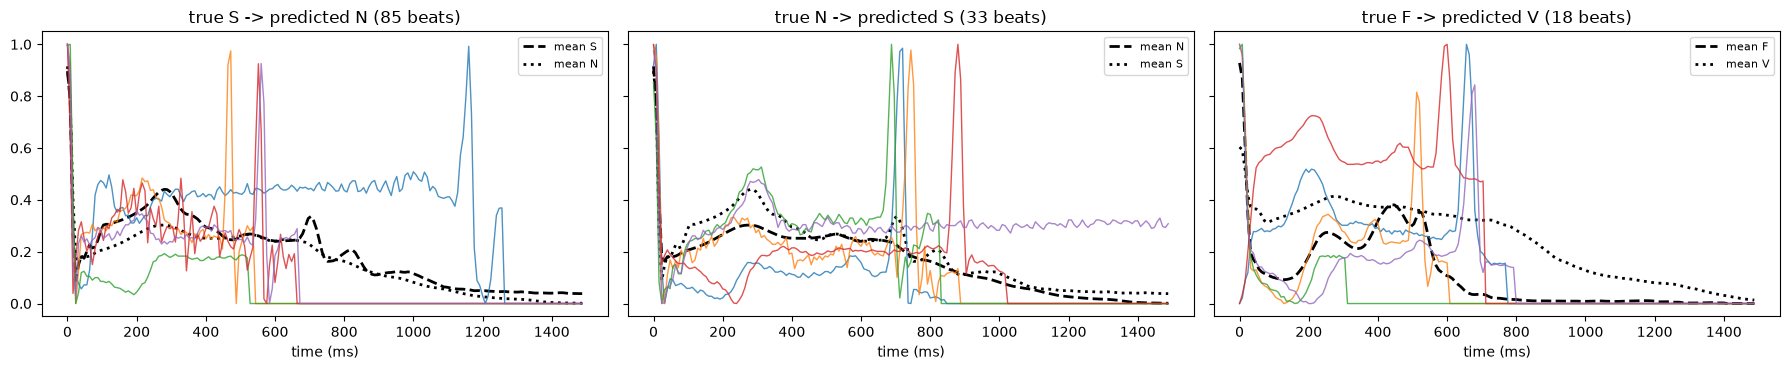

In [14]:
# Most confused pair (off-diagonal) for the selected model
cm_best = CMS[best_name].copy()
off = cm_best.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"Most frequent confusion for {best_name}: true {CLASS_NAMES[i]} predicted as {CLASS_NAMES[j]} ({off[i, j]} beats)")
pairs = sorted([(off[a, b] + off[b, a], CLASS_NAMES[a], CLASS_NAMES[b]) for a in range(5) for b in range(a + 1, 5)], reverse=True)[:4]
print("Most confused unordered pairs:", [(f"{a}<->{b}", n) for n, a, b in pairs])

pred_best = PREDS[best_name]
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8), sharey=True)
for ax, (ti, pj) in zip(axes, [(i, j), (j, i), (3, 2) if (i, j) != (3, 2) else (3, 0)]):
    wrong = np.flatnonzero((y_val == ti) & (pred_best == pj))[:5]
    ax.plot(t_axis, X_fit[y_fit == ti].mean(0), "k--", lw=2, label=f"mean {CLASS_NAMES[ti]}")
    ax.plot(t_axis, X_fit[y_fit == pj].mean(0), "k:", lw=2, label=f"mean {CLASS_NAMES[pj]}")
    for w in wrong:
        ax.plot(t_axis, X_val[w], lw=1, alpha=0.8)
    ax.set_title(f"true {CLASS_NAMES[ti]} -> predicted {CLASS_NAMES[pj]} ({len(np.flatnonzero((y_val == ti) & (pred_best == pj)))} beats)")
    ax.set_xlabel("time (ms)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Shifting the model towards catching V beats

Missing a ventricular (V) beat and wrongly flagging a normal (N) beat as V have different costs. With probabilistic output, a simple lever is to multiply the V-class probability by a weight *w* > 1 before taking the arg-max. Below I show the trade-off on the validation set for the CNN.

In [15]:
rows = []
for w in [1, 1.5, 2, 3, 5, 8]:
    p = cnn_val_proba.copy(); p[:, 2] *= w
    pr = p.argmax(1)
    v_true = y_val == 2
    rows.append({"V weight w": w, "V sensitivity": (pr[v_true] == 2).mean(),
                 "V missed": int((pr[v_true] != 2).sum()),
                 "N flagged as V": int(((y_val == 0) & (pr == 2)).sum()),
                 "V PPV": ((pr == 2) & v_true).sum() / max((pr == 2).sum(), 1),
                 "macro F1": f1_score(y_val, pr, average="macro")})
display(pd.DataFrame(rows).round(4))

,V weight w,V sensitivity,V missed,N flagged as V,V PPV,macro F1
0,1.0,0.9758,28,44,0.9354,0.9180
1,1.5,0.9801,23,61,0.9198,0.9172
2,2.0,0.9827,20,68,0.9111,0.9137
3,3.0,0.9853,17,81,0.8942,0.9065
4,5.0,0.9853,17,110,0.8677,0.8995
5,8.0,0.9870,15,135,0.8460,0.8954


### Part D — answers

**Why macro F1 instead of accuracy?** Accuracy is dominated by N (83% of beats): the useless majority classifier already scores 0.828, and unweighted logistic regression reaches 0.913 while missing two-thirds of V beats. Macro F1 averages F1 *equally* across the five classes, so failing on the rare classes S and F pulls it down hard (majority = 0.181). **What it still hides:** (1) it weights all classes equally, regardless of clinical importance; (2) it combines sensitivity and precision into one number, hiding which of the two is poor; (3) it does not show *which* classes are confused with which; (4) it says nothing about calibration or per-patient performance. The confusion matrix and per-class table are still needed.

**Most confused pair: N ↔ S** (118 beats for the CNN; the single largest cell is **85 true S beats predicted N**), followed by N ↔ V (66) and V ↔ F (23). The plotted misclassified S beats look almost identical to the mean N beat. A supraventricular ectopic beat starts above the ventricles, so its QRS complex is normally narrow and normal-looking. Its defining feature is *prematurity* (a short preceding RR interval) and sometimes an abnormal or hidden P wave. A single-beat window starting at the R peak barely contains the preceding interval, so the information needed is largely absent. Similarly, F beats are by definition hybrids of N and V morphology and fall between them.

**Missing a V beat vs flagging an N beat as V.** I would rather reduce **missed V beats**. Frequent or runs of ventricular ectopic beats can precede dangerous ventricular arrhythmias, so a miss can hide clinically important information, while a false V flag costs a reviewer a few seconds. To shift the model, I multiply the V probability by a weight *w* before the arg-max (equivalently, lower the V decision threshold). Other options are a class weight for V in the loss, or cost-sensitive training. The table shows the trade-off: at *w* = 2, missed V beats drop from 28 to 20 (sensitivity 0.976 → 0.983), while N beats flagged as V rise from 44 to 68 and V PPV falls 0.935 → 0.911. Beyond *w* ≈ 3 the gain flattens while false flags keep rising. The weight should be chosen on validation data with reviewers, not tuned on the test set.

## Part E — Final test (selected model only, used once)

,accuracy,macro_F1,sens_N,sens_S,sens_V,sens_F,sens_Q,PPV_N,PPV_S,PPV_V,PPV_F,PPV_Q,split,train_seconds
Majority baseline,0.828,0.181,1.000,0.000,0.000,0.000,0.000,0.828,0.000,0.000,0.000,0.000,validation,0.001
LogReg,0.913,0.657,0.982,0.447,0.332,0.289,0.890,0.925,0.822,0.629,0.673,0.936,validation,5.567
LogReg balanced,0.674,0.482,0.644,0.694,0.737,0.852,0.935,0.973,0.152,0.298,0.080,0.718,validation,7.665
RF raw,0.975,0.875,0.998,0.613,0.891,0.609,0.956,0.975,0.975,0.967,0.918,0.993,validation,21.706
RF features,0.973,0.865,0.997,0.580,0.890,0.602,0.946,0.973,0.949,0.966,0.906,0.992,validation,4.754
1D CNN (NumPy),0.985,0.918,0.994,0.780,0.976,0.742,0.991,0.991,0.911,0.935,0.888,0.997,validation,138.398
MLP (sklearn),0.977,0.883,0.994,0.692,0.913,0.672,0.976,0.982,0.865,0.946,0.851,0.983,validation,4.286
1D CNN (NumPy) — TEST,0.983,0.902,0.994,0.732,0.970,0.698,0.979,0.988,0.893,0.935,0.863,0.998,TEST (once),NaN


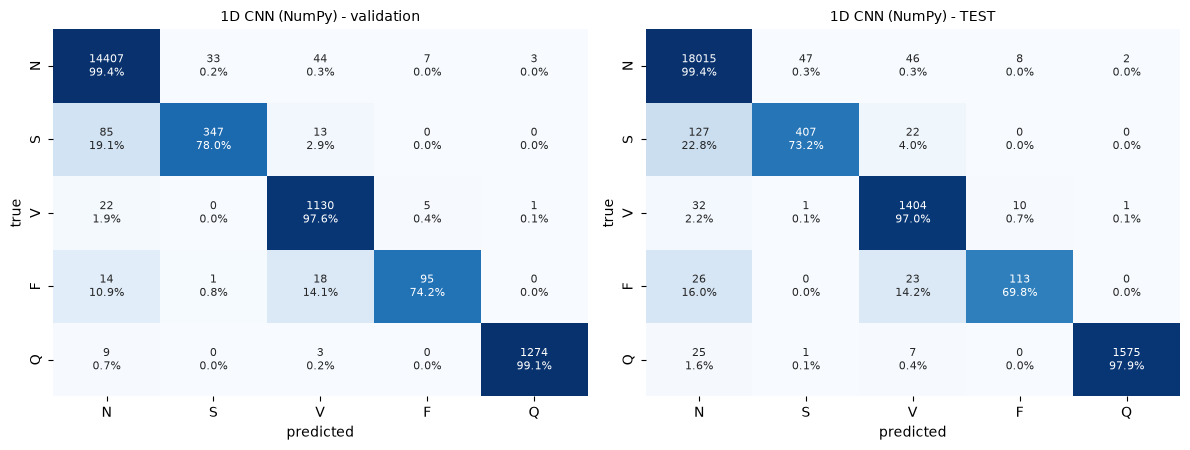

,accuracy,macro_F1,sens_N,sens_S,sens_V,sens_F,sens_Q,PPV_N,PPV_S,PPV_V,PPV_F,PPV_Q
validation,0.985,0.918,0.994,0.780,0.976,0.742,0.991,0.991,0.911,0.935,0.888,0.997
test,0.983,0.902,0.994,0.732,0.970,0.698,0.979,0.988,0.893,0.935,0.863,0.998


In [16]:
selected = {"1D CNN (NumPy)": lambda X: cnn.predict(X),
            "RF raw": lambda X: rf_raw.predict(X),
            "RF features": lambda X: rf_feat.predict(beat_features(X)),
            "MLP (sklearn)": lambda X: mlp.predict(X),
            "LogReg balanced": lambda X: logreg_bal.predict(X),
            "LogReg": lambda X: logreg.predict(X)}[best_name]
test_pred = selected(X_test)
test_row = evaluate(f"{best_name} — TEST", y_test, test_pred, store=False)
cm_test = confusion_matrix(y_test, test_pred, labels=range(5))

final_tbl = pd.DataFrame(RESULTS).T
final_tbl["split"] = "validation"
final_tbl.loc[f"{best_name} — TEST"] = {**test_row, "split": "TEST (once)"}
final_tbl["train_seconds"] = pd.Series(TIMES)
display(final_tbl.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
plot_cm(CMS[best_name], f"{best_name} - validation", axes[0])
plot_cm(cm_test, f"{best_name} - TEST", axes[1])
plt.tight_layout(); plt.show()

vt = pd.DataFrame({"validation": RESULTS[best_name], "test": test_row}).T
display(vt.round(3))

Lowest test sensitivity: class F (0.698)
Missed F beats were predicted as: {'N': 26, 'V': 23}


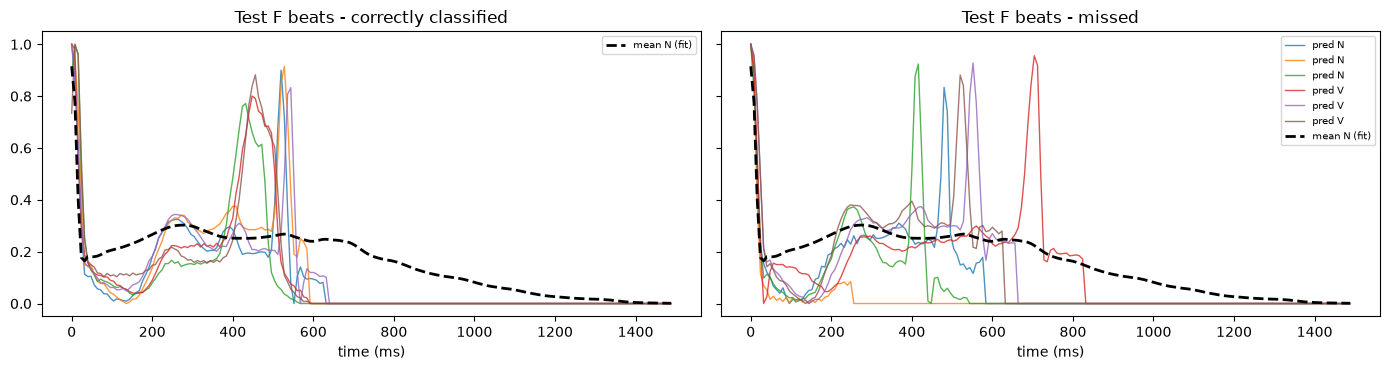

In [17]:
sens_test = np.array([test_row[f"sens_{c}"] for c in CLASS_NAMES])
worst = int(sens_test.argmin())
print(f"Lowest test sensitivity: class {CLASS_NAMES[worst]} ({sens_test[worst]:.3f})")
missed = np.flatnonzero((y_test == worst) & (test_pred != worst))
caught = np.flatnonzero((y_test == worst) & (test_pred == worst))
print("Missed", CLASS_NAMES[worst], "beats were predicted as:",
      pd.Series([CLASS_NAMES[k] for k in test_pred[missed]]).value_counts().to_dict())
rng_e = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, idx, title in [(axes[0], caught, "correctly classified"), (axes[1], missed, "missed")]:
    for k in rng_e.choice(idx, min(6, len(idx)), replace=False):
        ax.plot(t_axis, X_test[k], lw=1, alpha=0.8,
                label=f"pred {CLASS_NAMES[test_pred[k]]}" if title == "missed" else None)
    ax.plot(t_axis, X_fit[y_fit == 0].mean(0), "k--", lw=2, label="mean N (fit)")
    ax.set_title(f"Test {CLASS_NAMES[worst]} beats - {title}"); ax.set_xlabel("time (ms)")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### Part E — answers

**Test results (1D CNN, evaluated once):** accuracy **0.983** and macro F1 **0.902**. Sensitivities: N 0.994, S 0.732, V 0.970, F 0.698, Q 0.979. PPVs: 0.988 / 0.893 / 0.935 / 0.863 / 0.998. These are slightly below validation (macro F1 0.918 → 0.902), most visibly for S (0.78 → 0.73) and F (0.74 → 0.70). The small drop is expected because the validation set was used for early stopping and model selection, and S and F have few beats (556 and 162 in test), so their sensitivities are noisy: one F beat ≈ 0.6 percentage points.

**Lowest test sensitivity: F (0.698).** Of the 49 missed F beats, 26 were called N and 23 called V. The plots show that missed F beats sit visually between the N and V templates, consistent with a fusion beat being a mix of normal and ventricular activation.

**Did test performance match validation?** Yes, closely. **That does not show performance on new patients.** Both the validation set (a random beat-level split of the training file) and the Kaggle test file are drawn from the *same* pool of 47 people. The test file is very likely to contain beats from the same people as the training file (the class proportions match to 0.01%, consistent with a random beat-level split). The model is therefore tested mostly on *new beats from familiar hearts*. Both estimates share the same optimistic bias, so they agree with each other while both overstating performance on a new patient.

## Part F — Reflection

**Beat-level results overstate real performance.** A person's beats are very similar to each other: same heart, electrode placement and noise. Because these files split beats at random, a test beat almost always has near-copies from the same person in training, and the model can partly recognise *people* rather than learn general morphology. de Chazal et al. (2004) instead split MIT-BIH **by record** (DS1/DS2), so that training and test patients differ. Under that "inter-patient" protocol, published scores drop substantially, especially for S and F beats, where sensitivity can fall to well below 50% because their appearance varies between people. I would expect my macro F1 of ~0.90 to fall a long way, with S and F affected most.

**Before clinical use** the tool would need: its own beat detection and segmentation on raw continuous ECG (here beats were pre-extracted and R peaks given); robustness to noise and artefacts, other leads and devices (MIT-BIH is mostly a modified lead II, recorded in the 1970s); training and validation on far more and more diverse patients (age, sex, ethnicity, comorbidities, pacemakers); and **external validation** on independent databases with patient-level splits. Prospective evaluation in the intended Holter workflow, and regulatory review, would also be required.

**Workflow fit:** the tool should only **rank or highlight** beats for a cardiac technician or cardiologist, who confirms every label and writes the report. It must never be the sole basis for a diagnosis. Errors should be expected: reviewers need easy correction, sampled audits of beats labelled N (where misses hide), and monitoring of disagreement rates. This notebook makes no claim of clinical readiness.